In [1]:
import sys
print(sys.executable)
!c:\Users\louis\anaconda3\envs\mlclass\python.exe -m pip install seaborn imbalanced-learn
%pip install scikit-learn
%pip install seaborn imbalanced-learn

C:\Users\jack\anaconda3\python.exe


The system cannot find the path specified.


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


# Data Cleansing

In [2]:
# Making sure all columns show
import pandas as pd, numpy as np
from sklearn.svm import SVC
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE

from scipy.stats import pearsonr

df = pd.read_csv("adult.csv")

print(df.shape)
df.info()
df.describe(include='all')

(32561, 15)
<class 'pandas.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             32561 non-null  int64
 1   workclass       32561 non-null  str  
 2   fnlwgt          32561 non-null  int64
 3   education       32561 non-null  str  
 4   education.num   32561 non-null  int64
 5   marital.status  32561 non-null  str  
 6   occupation      32561 non-null  str  
 7   relationship    32561 non-null  str  
 8   race            32561 non-null  str  
 9   sex             32561 non-null  str  
 10  capital.gain    32561 non-null  int64
 11  capital.loss    32561 non-null  int64
 12  hours.per.week  32561 non-null  int64
 13  native.country  32561 non-null  str  
 14  income          32561 non-null  str  
dtypes: int64(6), str(9)
memory usage: 6.2 MB


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
count,32561.000000,32561,3.256100e+04,32561,32561.000000,32561,32561,32561,32561,32561,32561.000000,32561.000000,32561.000000,32561,32561
unique,NaN,9,NaN,16,NaN,7,15,6,5,2,NaN,NaN,NaN,42,2
top,NaN,Private,NaN,HS-grad,NaN,Married-civ-spouse,Prof-specialty,Husband,White,Male,NaN,NaN,NaN,United-States,<=50K
freq,NaN,22696,NaN,10501,NaN,14976,4140,13193,27816,21790,NaN,NaN,NaN,29170,24720
mean,38.581647,NaN,1.897784e+05,NaN,10.080679,NaN,NaN,NaN,NaN,NaN,1077.648844,87.303830,40.437456,NaN,NaN
std,13.640433,NaN,1.055500e+05,NaN,2.572720,NaN,NaN,NaN,NaN,NaN,7385.292085,402.960219,12.347429,NaN,NaN
min,17.000000,NaN,1.228500e+04,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,1.000000,NaN,NaN
25%,28.000000,NaN,1.178270e+05,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
50%,37.000000,NaN,1.783560e+05,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,40.000000,NaN,NaN
75%,48.000000,NaN,2.370510e+05,NaN,12.000000,NaN,NaN,NaN,NaN,NaN,0.000000,0.000000,45.000000,NaN,NaN


In [3]:
# For some reason this dataset has missing values as ?, so we're replacing them with NAN.
df = df.replace("?", np.nan)
# strip whitespace from all text columns
for c in df.select_dtypes(include=['object', 'str']).columns:
    df[c] = df[c].str.strip()

In [4]:
# Drop all missing values
df = df.dropna()

In [5]:
# Remove duplicates
df = df.drop_duplicates()

In [6]:
# Dropping Education since education.num is essentially an encoded numeric representation that's easier to work with. Here is the matching:
'''
Preschool	1
1st-4th	2
5th-6th	3
7th-8th	4
9th	5
10th	6
11th	7
12th	8
HS-grad	9
Some-college	10
Assoc-voc	11
Assoc-acdm	12
Bachelors	13
Masters	14
Prof-school	15
Doctorate	16
'''
# Also dropping fnlwgt since its just a sampling weight. Additionally dropping capital gain/loss.
df = df.drop(columns=['education', 'fnlwgt', 'capital.gain', 'capital.loss'])

In [7]:
# Encoding income to be binary, 0 if less than 50k, 1 if more.
df['income'] = df['income'].map({'<=50K': 0, '>50K': 1})

In [8]:
# Turning native country into either US or Other, since its 90% U.S
df['native.country'] = np.where(df['native.country']=='United-States', 'US', 'Other')

In [9]:
# Turning all the string values into binary values (one hot encoding)

df_raw = df.copy() # making a copy for later

df = pd.get_dummies(df, columns=['workclass','marital.status','occupation',
                                 'relationship','race','sex','native.country'],
                    drop_first=True)


In [10]:
print(*(f"{col}: {dtype}" for col, dtype in zip(df.columns, df.dtypes)), sep="\n")

age: int64
education.num: int64
hours.per.week: int64
income: int64
workclass_Local-gov: bool
workclass_Private: bool
workclass_Self-emp-inc: bool
workclass_Self-emp-not-inc: bool
workclass_State-gov: bool
workclass_Without-pay: bool
marital.status_Married-AF-spouse: bool
marital.status_Married-civ-spouse: bool
marital.status_Married-spouse-absent: bool
marital.status_Never-married: bool
marital.status_Separated: bool
marital.status_Widowed: bool
occupation_Armed-Forces: bool
occupation_Craft-repair: bool
occupation_Exec-managerial: bool
occupation_Farming-fishing: bool
occupation_Handlers-cleaners: bool
occupation_Machine-op-inspct: bool
occupation_Other-service: bool
occupation_Priv-house-serv: bool
occupation_Prof-specialty: bool
occupation_Protective-serv: bool
occupation_Sales: bool
occupation_Tech-support: bool
occupation_Transport-moving: bool
relationship_Not-in-family: bool
relationship_Other-relative: bool
relationship_Own-child: bool
relationship_Unmarried: bool
relationship

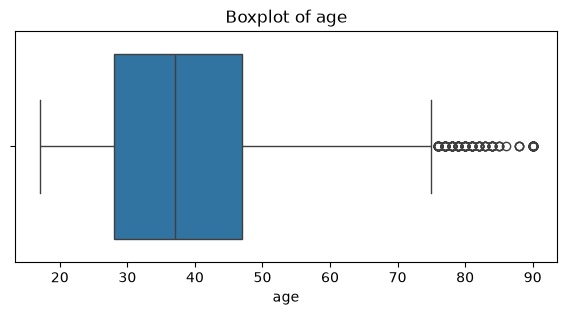

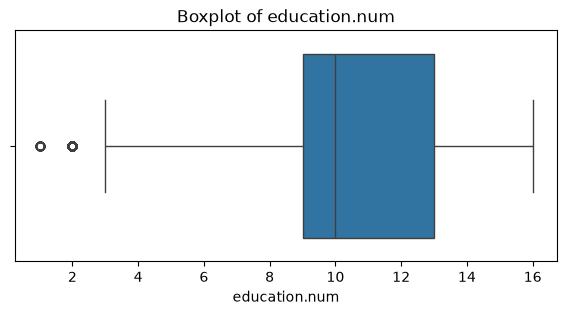

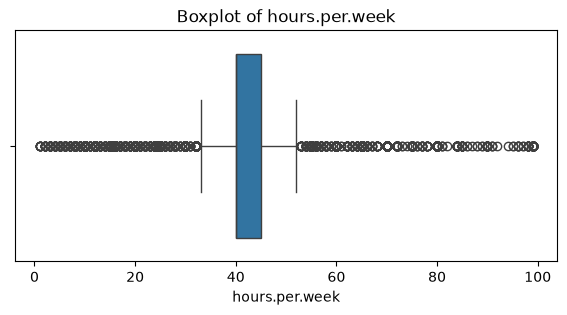

In [11]:
# Check for Outliers using boxplots
numerical_cols = df.select_dtypes(
    include=['int64', 'float64']
).columns.drop('income', errors='ignore')

for col in numerical_cols:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

In [12]:
# Check for Outliers numerically
outlier_results = []

for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    outlier_results.append({
        'Column': col,
        'Q1': Q1,
        'Q3': Q3,
        'IQR': IQR,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outlier Count': len(outliers),
        'Outlier Percentage': round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

outlier_summary

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,28.0,47.0,19.0,-0.5,75.5,168,0.56
1,education.num,9.0,13.0,4.0,3.0,19.0,193,0.64
2,hours.per.week,40.0,45.0,5.0,32.5,52.5,7947,26.37


In [13]:
# Investigate outliers. Age and education.num outliers are realistic and not IMPOSSIBLE. Will check hours per week if anything exceeds 168
invalid_hours = df[df['hours.per.week'] > 168]
print("Invalid records:", len(invalid_hours))

Invalid records: 0


### Feature Engineering

New Features being made: 

Age groups | For identifying people in similar stages to life and career -> Young, Adult, Middle Aged, Old. Meant to help with lack of data in higher and lower age brackets

Education Groups | The education num treats the difference between 9th and 10th grade to be the same as having or not having a degree/diploma. These new features split based off of what degree the person has which relates to jobs they are qualified for

Education x Hours Worked | This feature evaluates the amount of hours worked by an individual in conjunction with their education. More highly educated workers often earn more than lower educated workers per hour worked and this should counterbalance the model identifying more hours worked as always being higher income or vice versa

In [14]:
# Age brackets (raw age)
bins = [0, 25, 40, 60, 200]
labels = ['very_young', 'young', 'middle_aged', 'old']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels, right=False)
print("Unassigned ages:", df['age_group'].isna().sum())  # must be 0
df = pd.get_dummies(df, columns=['age_group'], drop_first=True)

# Education brackets (raw education.num)
bins = [0, 9, 13, 14, 15, 17]
labels = ['no_degree', 'low_degree', 'bachelors', 'masters', 'doctorate']
df['education_category'] = pd.cut(df['education.num'], bins=bins, labels=labels, right=False)
print("Unassigned education:", df['education_category'].isna().sum())  # must be 0
df = pd.get_dummies(df, columns=['education_category'], drop_first=True)

# education.num x hours.per.week
df['education.by.hours.worked'] = df['education.num'] * df['hours.per.week']
print("Max product:", df['education.by.hours.worked'].max())
df['education.by.hours.worked'] = df['education.by.hours.worked'] / 1584
df.head()

Unassigned ages: 0
Unassigned education: 0
Max product: 1584


,age,education.num,hours.per.week,income,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,...,sex_Male,native.country_US,age_group_young,age_group_middle_aged,age_group_old,education_category_low_degree,education_category_bachelors,education_category_masters,education_category_doctorate,education.by.hours.worked
1,82,9,18,0,False,True,False,False,False,False,...,False,True,False,False,True,True,False,False,False,0.102273
3,54,4,40,0,False,True,False,False,False,False,...,False,True,False,True,False,False,False,False,False,0.101010
4,41,10,40,0,False,True,False,False,False,False,...,False,True,False,True,False,True,False,False,False,0.252525
5,34,9,45,0,False,True,False,False,False,False,...,False,True,True,False,False,True,False,False,False,0.255682
6,38,6,40,0,False,True,False,False,False,False,...,True,True,True,False,False,False,False,False,False,0.151515


In [15]:
# Split dataset for training into 80/20 data,
from sklearn.model_selection import train_test_split
X = df.drop(columns=['income'])
y = df['income']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

# Scale numeric features and fit the scaler on the training data
from sklearn.preprocessing import StandardScaler
num_cols = ['age','education.num', 'hours.per.week']

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols]  = scaler.transform(X_test[num_cols])

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train, y_train
)

# Check class distribution
print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
income
0    18106
1     6005
Name: count, dtype: int64

After SMOTE:
income
0    18106
1    18106
Name: count, dtype: int64


In [16]:
# Just making sure everything is good
print(X_train.isna().sum().sum(), "missing in train") 
print(X_train.dtypes.value_counts())
print(X_train.shape, X_test.shape)

0 missing in train
bool       43
float64     4
Name: count, dtype: int64
(24111, 47) (6028, 47)


# Analysis
Here we will analyze the data to gather relevant statistics.


In [17]:
analysis_Y = df_raw["income"].astype(int) 
analysis_X = df_raw.drop(columns=["income"])

## Check for Class Imbalance

In [18]:
print(analysis_Y.value_counts(normalize=True).round(3))

income
0    0.751
1    0.249
Name: proportion, dtype: float64


## Target distribution
Show class imabalance visually

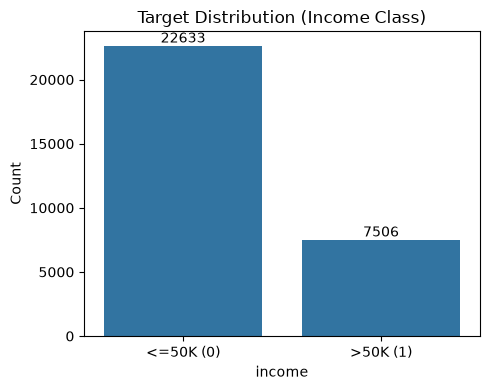

income
0    0.751
1    0.249
Name: proportion, dtype: float64


In [19]:
plt.figure(figsize=(5, 4))
ax = sns.countplot(x=df_raw['income'])
ax.set_xticks([0, 1]); ax.set_xticklabels(['<=50K (0)', '>50K (1)'])
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2, p.get_height()),
                ha='center', va='bottom')
plt.title('Target Distribution (Income Class)'); plt.ylabel('Count')
plt.tight_layout(); plt.show()

print(df_raw['income'].value_counts(normalize=True).round(3))

### Income rate by categorical features

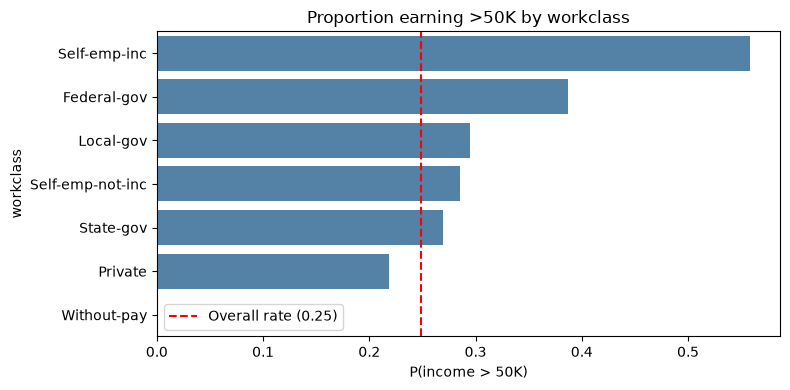

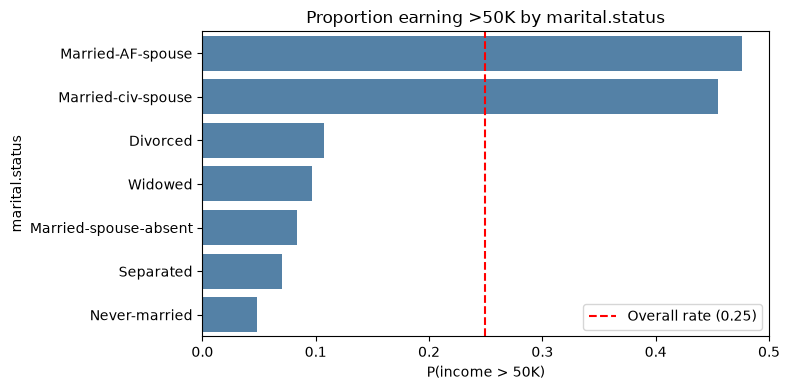

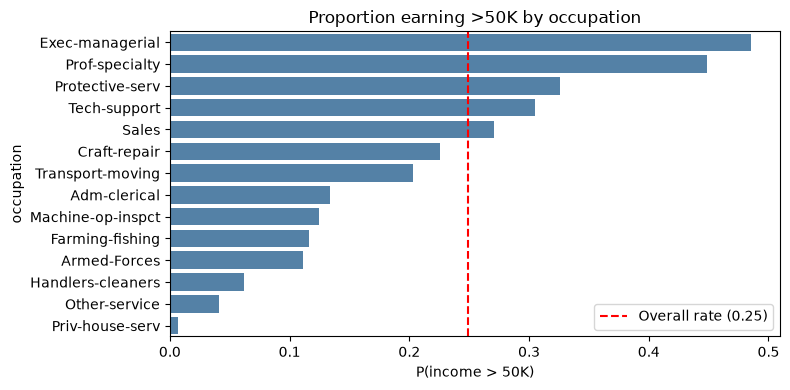

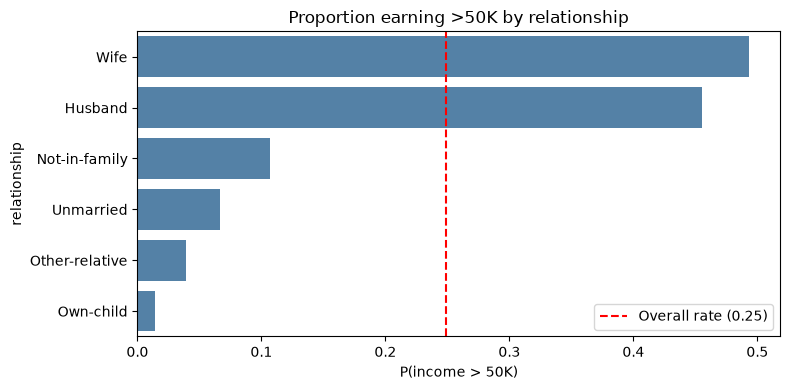

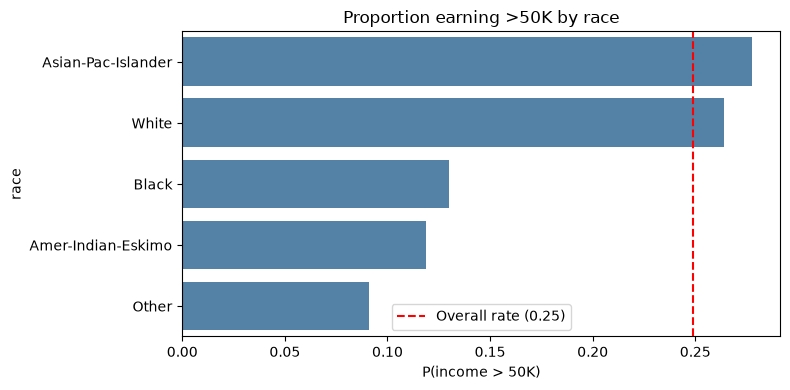

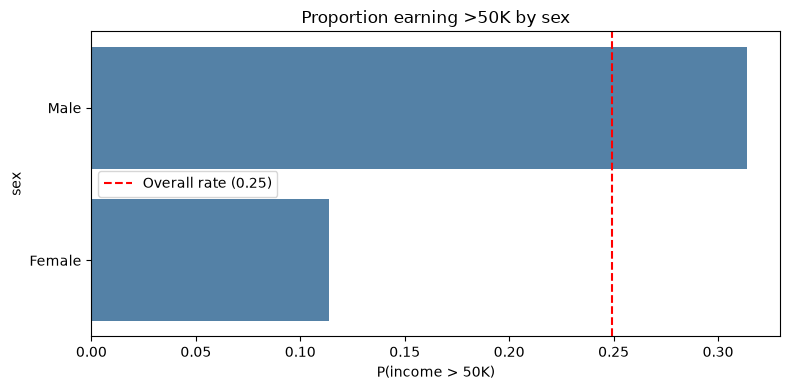

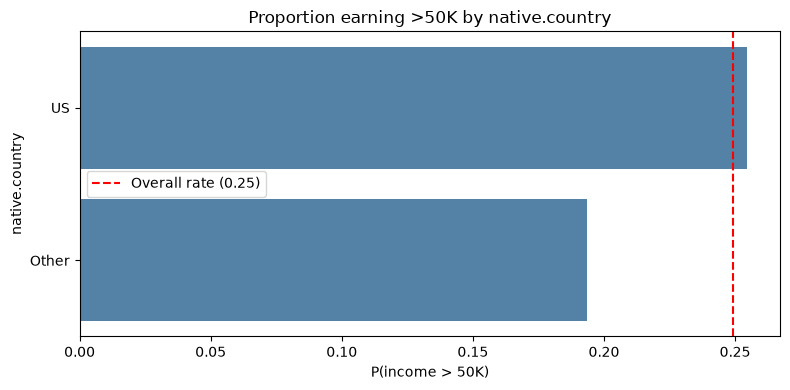

In [20]:
cat_features = ['workclass','marital.status','occupation',
                'relationship','race','sex','native.country']
overall = df_raw['income'].mean()

for col in cat_features:
    rate = df_raw.groupby(col)['income'].mean().sort_values(ascending=False)
    plt.figure(figsize=(8, 4))
    sns.barplot(x=rate.values, y=rate.index, color='steelblue')
    plt.axvline(overall, color='red', linestyle='--', label=f'Overall rate ({overall:.2f})')
    plt.title(f'Proportion earning >50K by {col}')
    plt.xlabel('P(income > 50K)'); plt.ylabel(col); plt.legend()
    plt.tight_layout(); plt.show()

### Income rate by education level

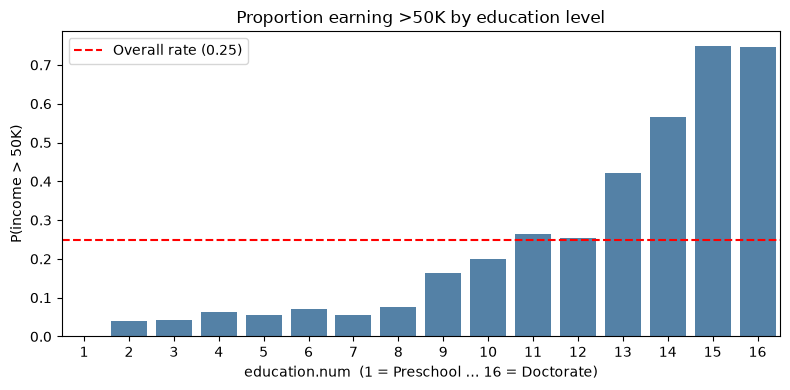

In [21]:
plt.figure(figsize=(8, 4))
edu_rate = df_raw.groupby('education.num')['income'].mean()
sns.barplot(x=edu_rate.index, y=edu_rate.values, color='steelblue')
plt.axhline(overall, color='red', linestyle='--', label=f'Overall rate ({overall:.2f})')
plt.title('Proportion earning >50K by education level')
plt.xlabel('education.num  (1 = Preschool … 16 = Doctorate)')
plt.ylabel('P(income > 50K)'); plt.legend()
plt.tight_layout(); plt.show()

### Numeric correlation heatmap

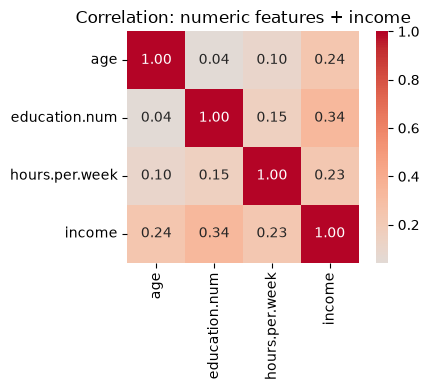

In [22]:
plt.figure(figsize=(5, 4))
corr = df_raw[['age', 'education.num', 'hours.per.week', 'income']].corr()
sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, fmt='.2f', square=True)
plt.title('Correlation: numeric features + income')
plt.tight_layout(); plt.show()

### Numeric features by income boxplots

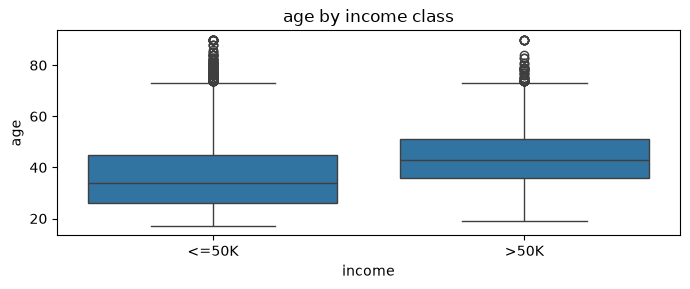

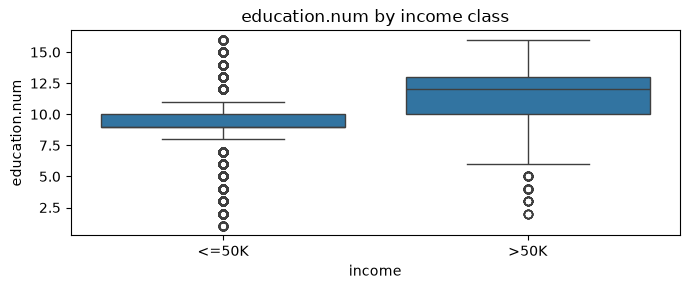

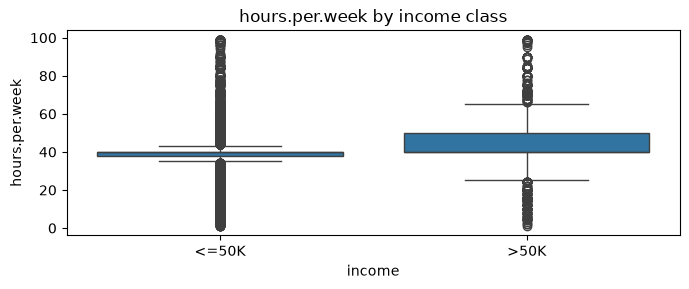

In [23]:
for col in ['age', 'education.num', 'hours.per.week']:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x='income', y=col, data=df_raw)
    plt.xticks([0, 1], ['<=50K', '>50K'])
    plt.title(f'{col} by income class')
    plt.tight_layout(); plt.show()

There appears to be some class imbalance, with 75% of the samples falling in the earnig less than 50k category.

### Check Pearson Correlation Coef against Target 
for Numerical features

In [24]:
num_assoc = analysis_X[num_cols].corrwith(analysis_Y).sort_values(key=abs, ascending=False)
print(num_assoc.round(3))


education.num     0.335
age               0.242
hours.per.week    0.229
dtype: float64


No single feature has too high of a correlation against the target (>0.75), indicating that these features do not need to be removed for being overly correlated.

### Check Chi2 P value against Target

for Categorical features


In [25]:
from scipy.stats import chi2_contingency

rows = []
for c in num_cols:
    chi2, p, dof, _ = chi2_contingency(pd.crosstab(analysis_X[c], analysis_Y))
    rows.append({"column": c, "chi2": chi2, "dof": dof, "p_value": p})

chi_table = pd.DataFrame(rows).sort_values("chi2", ascending=False).reset_index(drop=True)
print(chi_table.to_string(index=False))

        column        chi2  dof  p_value
 education.num 4069.280020   15      0.0
           age 3182.201477   71      0.0
hours.per.week 2404.345452   93      0.0


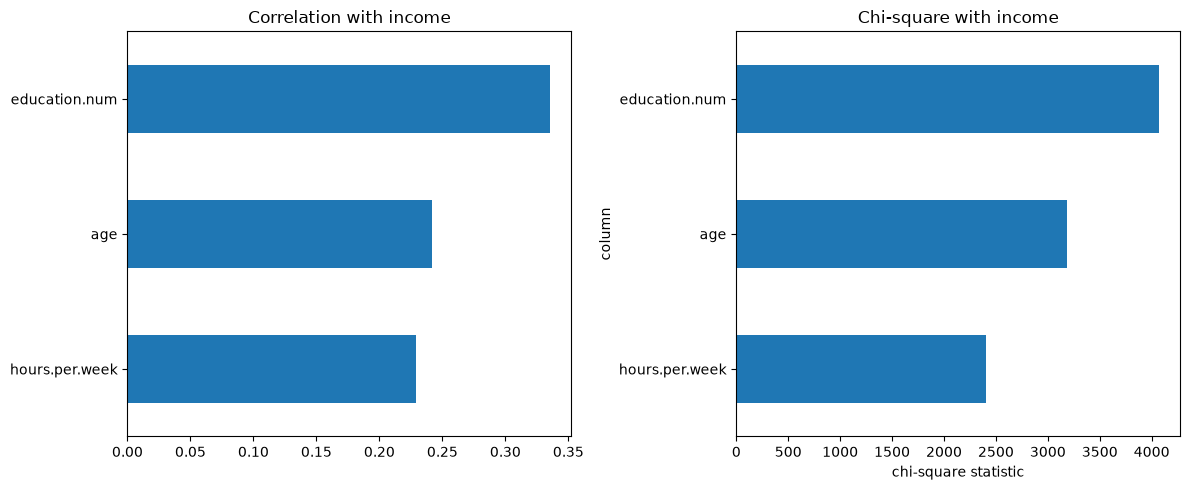

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
num_assoc.sort_values().plot(kind="barh", ax=axes[0])

axes[0].set_title("Correlation with income")
chi_table.sort_values("chi2").plot(kind="barh", x="column", y="chi2", ax=axes[1], legend=False)

axes[1].set_title("Chi-square with income")
axes[1].set_xlabel("chi-square statistic")
plt.tight_layout()
plt.show()

According to the Chi-square statistics and p-values, every categorical variable shows signs of association with the target variable, meaning that we do not need to remove it for being irrelevant.

In [27]:
for _, row in chi_table.iterrows():
    print(f"{row['column']}: is under 0.05? {row['p_value'] < 0.05}")

# Numeric columns (Pearson p-values)
for c in num_cols:
    r, p = pearsonr(analysis_X[c], analysis_Y)
    print(f"{c}: is under 0.05? {p < 0.05}")

education.num: is under 0.05? True
age: is under 0.05? True
hours.per.week: is under 0.05? True
age: is under 0.05? True
education.num: is under 0.05? True
hours.per.week: is under 0.05? True


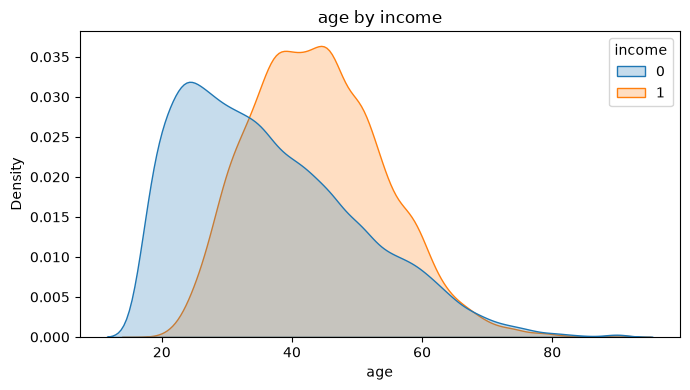

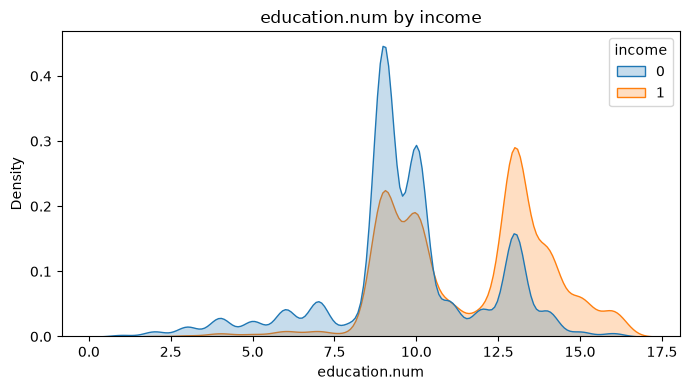

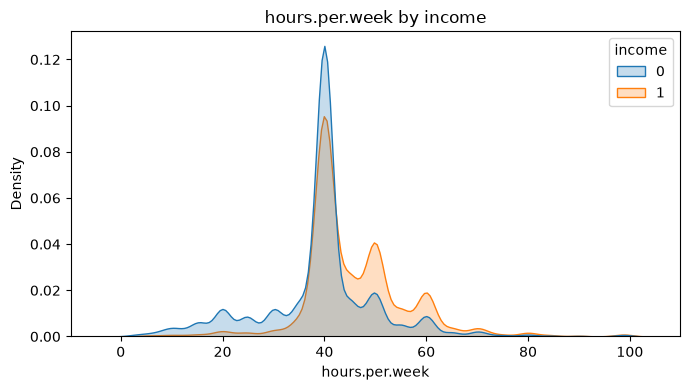

In [28]:
plot_df = analysis_X[num_cols].assign(income=analysis_Y)

for c in num_cols:
    plt.figure(figsize=(7, 4))
    sns.kdeplot(data=df_raw, x=c, hue="income", common_norm=False, fill=True)
    plt.title(f"{c} by income")
    plt.tight_layout()
    plt.show()

We plot the distributions of each numerical value for each population, to quickly glance and see if there are clear differences in distributions. This affirms that these are good features as the distributions between the two classes appear to be different, suggesting there is a correlation.

# Model 1: Decision Trees and Ensemble Learning

#### Decision Trees

              precision    recall  f1-score   support

           0       0.85      0.86      0.85      4527
           1       0.56      0.56      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



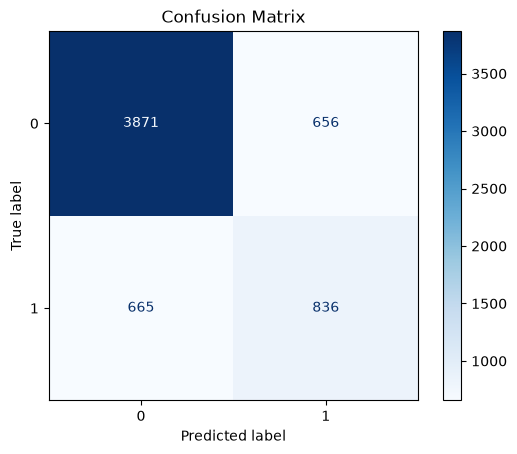

In [74]:
clf = tree.DecisionTreeClassifier()
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
disp.plot(cmap=plt.cm.Blues) 
plt.title("Confusion Matrix")
plt.show() 

Pre-smote decision trees have an almost equal number of false positives as false negatives, howver this means that the majority of the time a prediction for an income level of over 50k is incorrect. This requires improvement

              precision    recall  f1-score   support

           0       0.85      0.86      0.85      4527
           1       0.56      0.56      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



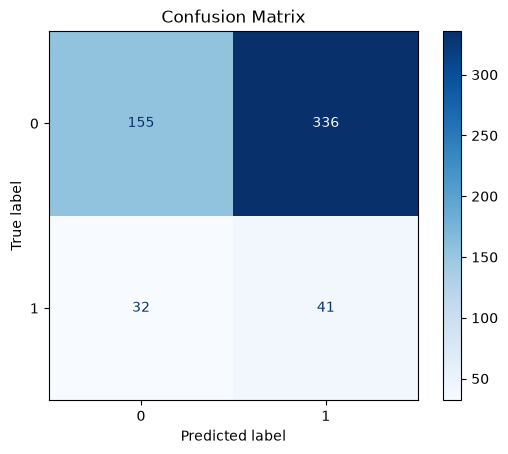

              precision    recall  f1-score   support

           0       0.85      0.86      0.85      4527
           1       0.56      0.56      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



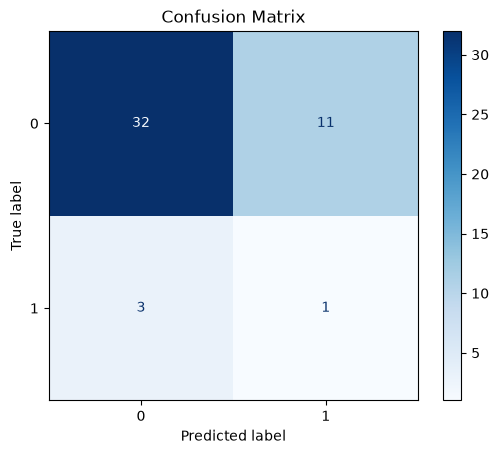

In [76]:
def predict_on_subset(col, val, model):
    df_subset = df[df[col] == val]
    X_subset = df_subset.drop(columns=['income'])
    y_subset = df_subset['income']
    X_train_subset, X_test_subset, y_train_subset, y_test_subset = train_test_split(
        X_subset, y_subset, test_size=0.2, random_state=42, stratify=y_subset)
    y_pred_subset = model.predict(X_test_subset)
    cm = confusion_matrix(y_test_subset, y_pred_subset)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(cmap=plt.cm.Blues) 
    print(classification_report(y_test, y_pred))
    plt.title("Confusion Matrix")
    plt.show() 
predict_on_subset('race_Black', True, clf)
predict_on_subset('race_Other', True, clf)

The racial bias of the baseline decision tree appears to be towards over predicting higher incomes. SMOTE should help balance this.

In [38]:
def test_model(clf):
    y_pred = clf.predict(X_test)
    print(classification_report(y_test, y_pred))
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[0, 1])
    disp.plot(cmap=plt.cm.Blues) 
    plt.title("Confusion Matrix")
    plt.show() 

Fitting 5 folds for each of 1440 candidates, totalling 7200 fits
Best Decision Tree params: {'ccp_alpha': np.float64(0.0), 'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 8, 'min_samples_leaf': 30}
Best CV F1: 0.6571
              precision    recall  f1-score   support

           0       0.93      0.75      0.83      4527
           1       0.53      0.84      0.65      1501

    accuracy                           0.78      6028
   macro avg       0.73      0.80      0.74      6028
weighted avg       0.83      0.78      0.79      6028



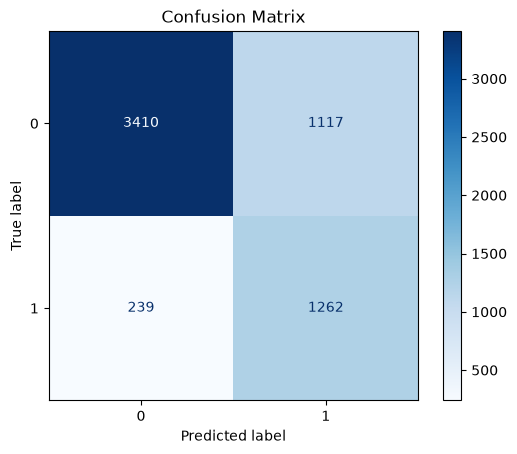

In [78]:
base_tree = DecisionTreeClassifier(random_state=42)
path = base_tree.cost_complexity_pruning_path(X_train, y_train)

alphas = np.clip(path.ccp_alphas[:-1], 0.0, None)
candidate_alphas = np.unique(np.quantile(alphas, np.linspace(0, 0.99, 15)))

param_grid = {
    "criterion": ["gini", "entropy"],
    "max_depth": [4, 6, 8, 12, 16, None],
    "min_samples_leaf": [1, 5, 15, 30],
    "ccp_alpha": candidate_alphas,
    "class_weight": [None, "balanced"],
}

dt_grid = GridSearchCV(
    DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1,
)

dt_grid.fit(X_train, y_train)

print("Best Decision Tree params:", dt_grid.best_params_)
print("Best CV F1:", round(dt_grid.best_score_, 4))

test_model(dt_grid)

The grid search version is poor at predicting the negative class more than any other but out of decision trees it seems to do the best at idenityfing a majority of the positive classes.

              precision    recall  f1-score   support

           0       0.87      0.92      0.89      4527
           1       0.70      0.58      0.64      1501

    accuracy                           0.83      6028
   macro avg       0.79      0.75      0.77      6028
weighted avg       0.83      0.83      0.83      6028



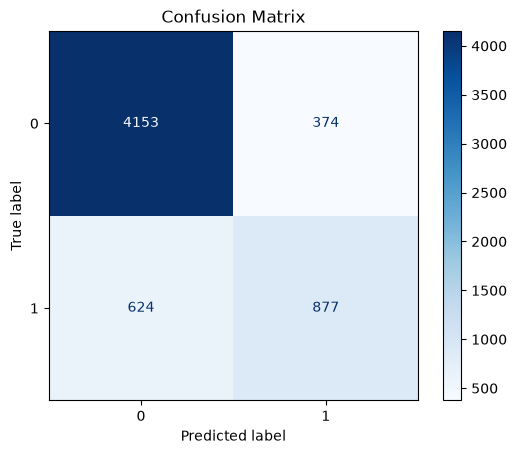

              precision    recall  f1-score   support

           0       0.92      0.78      0.85      4527
           1       0.55      0.80      0.65      1501

    accuracy                           0.79      6028
   macro avg       0.74      0.79      0.75      6028
weighted avg       0.83      0.79      0.80      6028



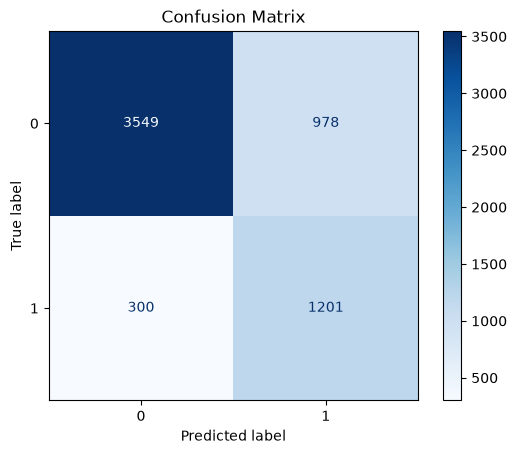

In [89]:
dt_unbalanced = tree.DecisionTreeClassifier(ccp_alpha= np.float64(0.0), criterion= 'gini', max_depth= 8, min_samples_leaf= 50)
dt_unbalanced.fit(X_train, y_train)
test_model(dt_unbalanced)

dt_unbalanced_smote = tree.DecisionTreeClassifier(ccp_alpha= np.float64(0.0), criterion= 'gini', max_depth= 8, min_samples_leaf= 50)
dt_unbalanced_smote.fit(X_train_smote, y_train_smote)
test_model(dt_unbalanced_smote)

After grid search for the most effective combination of hyperparameters, the decision tree was able to get to a point where just under 50% of its positive predictions are accurate. Still not great but certainly an improvement. The addition of SMOTE demonstrates a significant improvement due to fixing the class imbalance with fewer false positives and only slightly more false negatives. However, there is still a large number of false positives.

## Method 1B: Ensemble Techniques - Boosting

              precision    recall  f1-score   support

           0       0.88      0.91      0.89      4527
           1       0.69      0.61      0.65      1501

    accuracy                           0.84      6028
   macro avg       0.78      0.76      0.77      6028
weighted avg       0.83      0.84      0.83      6028



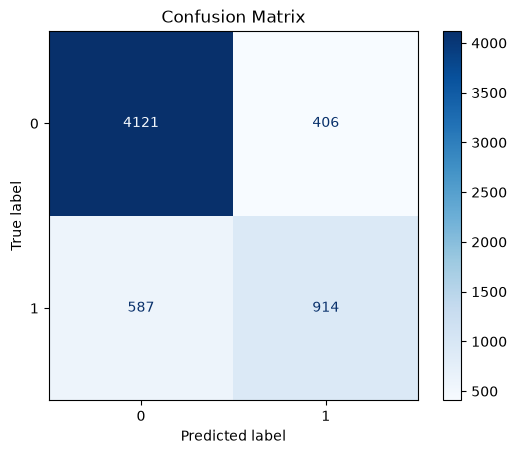

In [90]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
clf = HistGradientBoostingClassifier( learning_rate=0.05, max_iter=300, max_leaf_nodes=31, min_samples_leaf=20, l2_regularization=1.0, random_state=42)

clf.fit(X_train, y_train)
test_model(clf)

At a baseline, the boosting technique seems to increase the model's tendency to predict the negative class which should be fixed by SMOTE

              precision    recall  f1-score   support

           0       0.91      0.83      0.87      4527
           1       0.60      0.76      0.67      1501

    accuracy                           0.81      6028
   macro avg       0.76      0.80      0.77      6028
weighted avg       0.83      0.81      0.82      6028



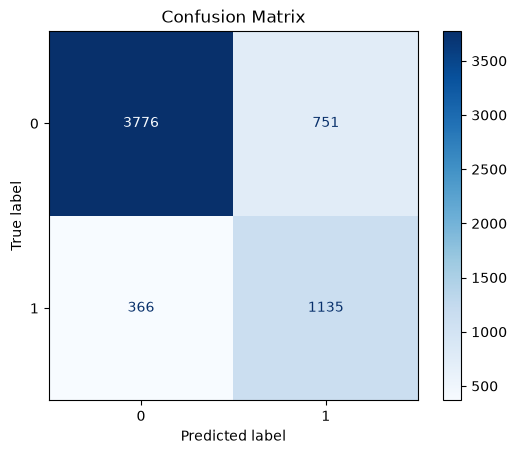

              precision    recall  f1-score   support

           0       0.91      0.84      0.87      4527
           1       0.61      0.75      0.67      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.80      0.77      6028
weighted avg       0.84      0.82      0.82      6028



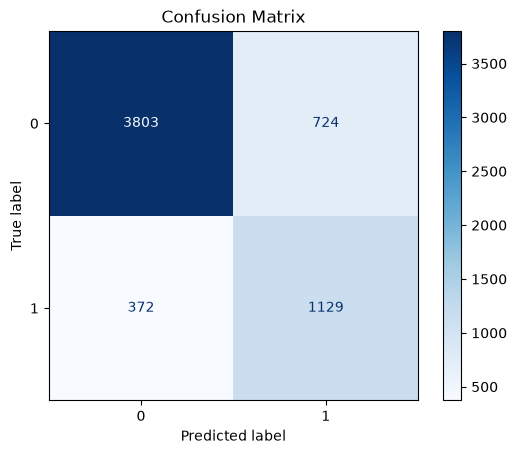

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best Decision Tree params: {'l2_regularization': 1.0, 'learning_rate': 0.05, 'max_iter': 500, 'min_samples_leaf': 5}
Best CV F1: 0.8598
              precision    recall  f1-score   support

           0       0.91      0.85      0.88      4527
           1       0.61      0.74      0.67      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.79      0.77      6028
weighted avg       0.83      0.82      0.82      6028



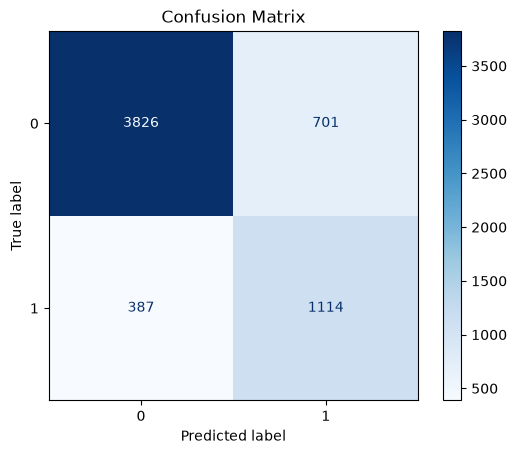

Fitting 5 folds for each of 100 candidates, totalling 500 fits
Best Decision Tree params: {'l2_regularization': 1.0, 'learning_rate': 0.05, 'max_iter': 500, 'min_samples_leaf': 5}
Best CV F1: 0.8619
              precision    recall  f1-score   support

           0       0.91      0.85      0.88      4527
           1       0.61      0.74      0.67      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.79      0.77      6028
weighted avg       0.83      0.82      0.82      6028



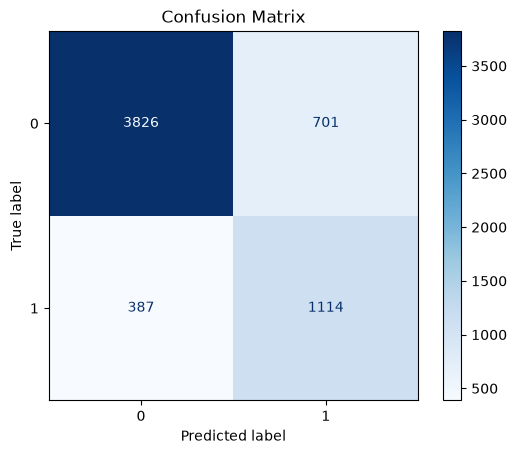

In [104]:
gb_smote = HistGradientBoostingClassifier( learning_rate=0.05, max_iter=300, max_leaf_nodes=31, min_samples_leaf=30, l2_regularization=1.0, random_state=42)
gb_smote.fit(X_train_smote, y_train_smote)
test_model(gb_smote)
gb_smote = HistGradientBoostingClassifier( learning_rate=0.02, max_iter=1000, max_leaf_nodes=31, min_samples_leaf=30, l2_regularization=1.0, random_state=42)
gb_smote.fit(X_train_smote, y_train_smote)
test_model(gb_smote)

param_grid = {
    "learning_rate": [0.01, 0.02, 0.03, 0.05],
    "min_samples_leaf": [1, 5, 15, 20, 30],
    "max_iter": [100, 200, 300, 400, 500],
    "l2_regularization": [1.0],
}

gb_grid_f1 = GridSearchCV(
    HistGradientBoostingClassifier(random_state=42),
    param_grid=param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1,
)

gb_grid_f1.fit(X_train_smote, y_train_smote)

print("Best Decision Tree params:", gb_grid_f1.best_params_)
print("Best CV F1:", round(gb_grid_f1.best_score_, 4))

test_model(gb_grid_f1)

gb_grid_ac = GridSearchCV(
    HistGradientBoostingClassifier(random_state=42),
    param_grid=param_grid,
    scoring="accuracy",
    cv=5,
    n_jobs=-1,
    verbose=1,
)

gb_grid_ac.fit(X_train_smote, y_train_smote)

print("Best Decision Tree params:", gb_grid_ac.best_params_)
print("Best CV F1:", round(gb_grid_ac.best_score_, 4))

test_model(gb_grid_ac)

With boosting on the SMOTE dataset and doing grid search for ideal hyperparameters, the model is performing better than any decision tree with an over 50% rate of being correct when predicting the positive class and nearly an 80% rate of identifying the positive class

## Model 1C: Bagging Classifier

In [44]:
from sklearn.ensemble import BaggingClassifier

              precision    recall  f1-score   support

           0       0.88      0.90      0.89      4527
           1       0.68      0.62      0.65      1501

    accuracy                           0.83      6028
   macro avg       0.78      0.76      0.77      6028
weighted avg       0.83      0.83      0.83      6028



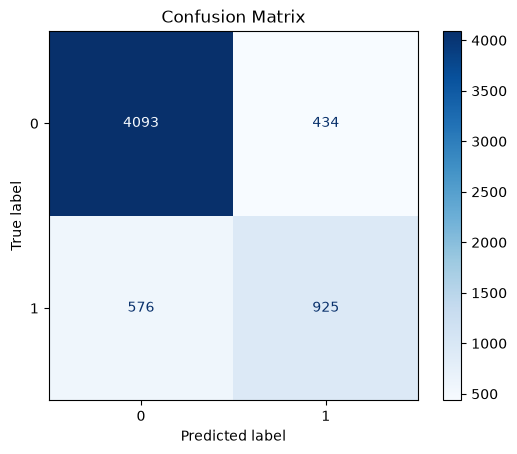

              precision    recall  f1-score   support

           0       0.91      0.82      0.87      4527
           1       0.59      0.76      0.66      1501

    accuracy                           0.81      6028
   macro avg       0.75      0.79      0.77      6028
weighted avg       0.83      0.81      0.82      6028



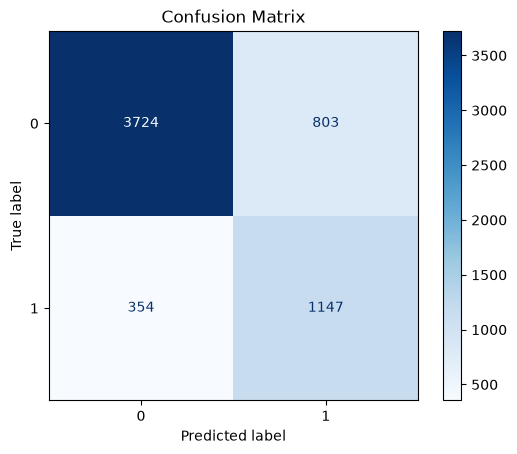

In [105]:
base_tree = tree.DecisionTreeClassifier(max_depth=15)
bagging_clf = BaggingClassifier(estimator=base_tree, n_estimators=50, max_samples=0.8, bootstrap=True, random_state=42)
bagging_clf.fit(X_train, y_train)
test_model(bagging_clf)

bagging_clf_smote = BaggingClassifier(estimator=base_tree, n_estimators=50, max_samples=0.8, bootstrap=True, random_state=42)
bagging_clf_smote.fit(X_train_smote, y_train_smote)
test_model(bagging_clf_smote)

              precision    recall  f1-score   support

           0       0.85      0.86      0.85      4527
           1       0.56      0.56      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



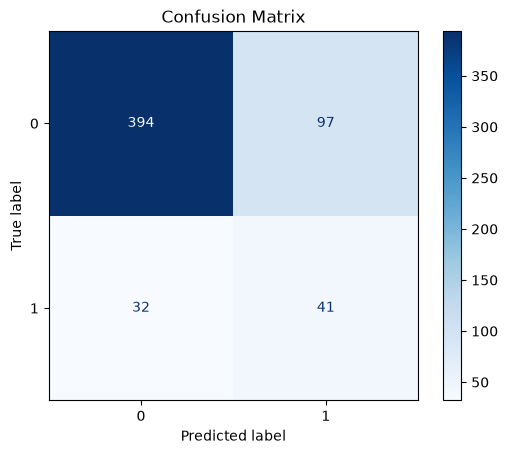

              precision    recall  f1-score   support

           0       0.85      0.86      0.85      4527
           1       0.56      0.56      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



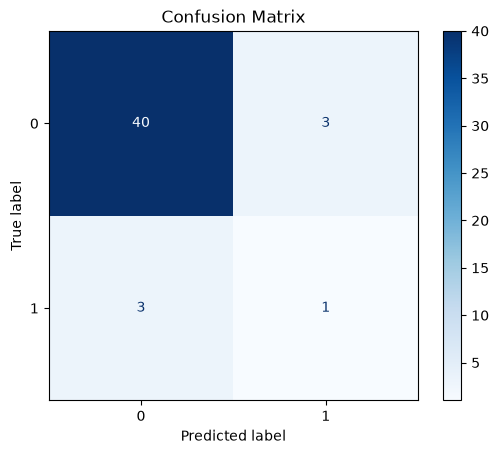

In [110]:
predict_on_subset('race_Black', True, bagging_clf_smote)
predict_on_subset('race_Other', True, bagging_clf_smote)

It seems like the bagging approach performed slightly worse than the previous boosting approach

## Model 1D: Stacking Approach

In [106]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

              precision    recall  f1-score   support

           0       0.86      0.90      0.88      4527
           1       0.65      0.55      0.60      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.73      0.74      6028
weighted avg       0.81      0.82      0.81      6028



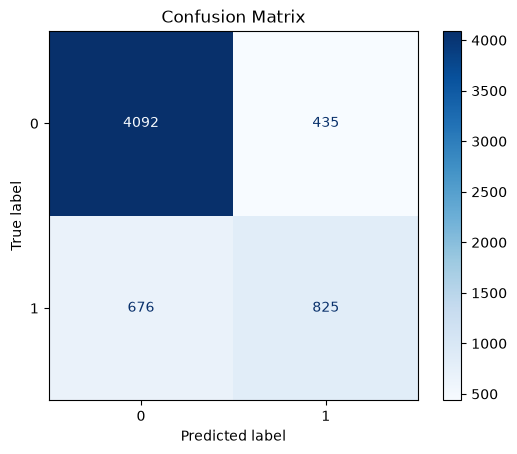

              precision    recall  f1-score   support

           0       0.89      0.85      0.87      4527
           1       0.60      0.67      0.63      1501

    accuracy                           0.81      6028
   macro avg       0.74      0.76      0.75      6028
weighted avg       0.81      0.81      0.81      6028



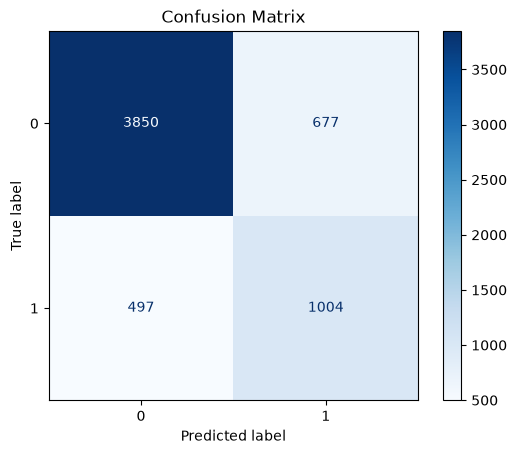

In [108]:
estimators = [
    ('random_forest', RandomForestClassifier(n_estimators=10, random_state=42)),
    ('decision_tree', DecisionTreeClassifier(max_depth=15, class_weight='balanced', random_state=42))
]
stacking_clf = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression())
stacking_clf.fit(X_train, y_train)
test_model(stacking_clf)

stacking_clf_smote = StackingClassifier(estimators=estimators, final_estimator=LogisticRegression())
stacking_clf_smote.fit(X_train_smote, y_train_smote)
test_model(stacking_clf_smote)

Using stacking led to a situation where there were far more false negatives and thus fewer correct predictions but also fewer false positives on the whole.

### Combining Ensemble Techniques

              precision    recall  f1-score   support

           0       0.90      0.85      0.88      4527
           1       0.62      0.71      0.66      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.78      0.77      6028
weighted avg       0.83      0.82      0.82      6028



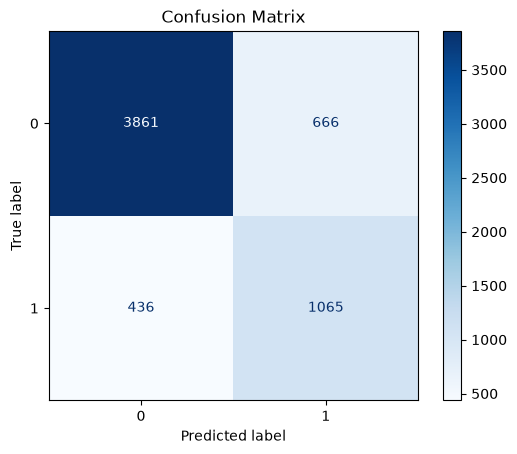

In [109]:
bagging_clf = BaggingClassifier(estimator=stacking_clf_smote, n_estimators=50, max_samples=0.8, bootstrap=True, random_state=42)
bagging_clf.fit(X_train_smote, y_train_smote)
test_model(bagging_clf)

              precision    recall  f1-score   support

           0       0.91      0.84      0.87      4527
           1       0.60      0.76      0.67      1501

    accuracy                           0.82      6028
   macro avg       0.76      0.80      0.77      6028
weighted avg       0.84      0.82      0.82      6028



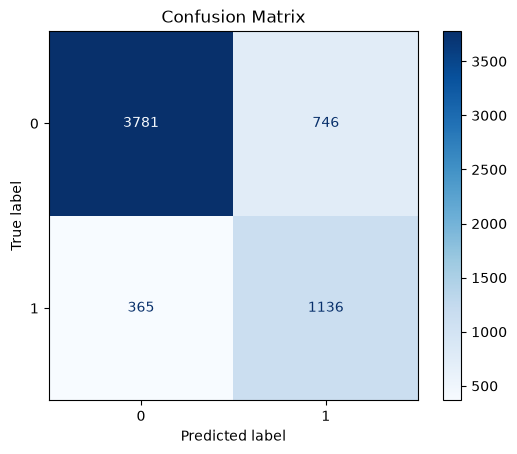

In [112]:
bagging_clf = BaggingClassifier(
    estimator=gb_grid_ac.best_estimator_,
    n_estimators=50,
    max_samples=0.8,
    bootstrap=True,
    n_jobs=-1,
    random_state=42,
)
bagging_clf.fit(X_train_smote, y_train_smote)
test_model(bagging_clf)

              precision    recall  f1-score   support

           0       0.85      0.86      0.85      4527
           1       0.56      0.56      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



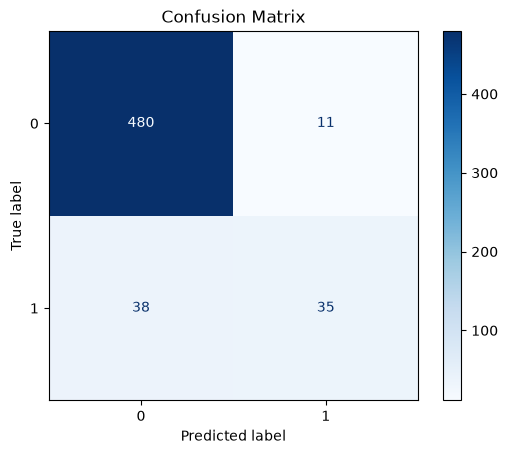

              precision    recall  f1-score   support

           0       0.85      0.86      0.85      4527
           1       0.56      0.56      0.56      1501

    accuracy                           0.78      6028
   macro avg       0.71      0.71      0.71      6028
weighted avg       0.78      0.78      0.78      6028



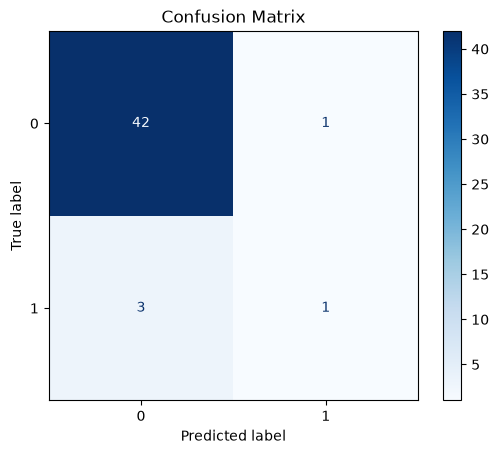

In [113]:
predict_on_subset('race_Black', True, bagging_clf)
predict_on_subset('race_Other', True, bagging_clf)

This model seems to perform the best overall, but appears to have a racial bias against black individuals

# Method 2: Logistic Regression with Grid Search



In [57]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, f1_score

In [58]:
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "l1_ratio": [0, 0.5, 1],
    "class_weight": [None, "balanced"],
}

# Without smote
grid_no_smote = GridSearchCV(
    LogisticRegression(solver="saga", max_iter=1000),
    param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1,
)
grid_no_smote.fit(X_train, y_train)
print("No SMOTE best params:", grid_no_smote.best_params_)
print("No SMOTE best CV F1:", round(grid_no_smote.best_score_, 4))

# With Smote
grid_smote = GridSearchCV(
    LogisticRegression(solver="saga", max_iter=1000),
    param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1,
)

grid_smote.fit(X_train_smote, y_train_smote)
print("SMOTE best params:", grid_smote.best_params_)
print("SMOTE best CV F1:", round(grid_smote.best_score_, 4))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
No SMOTE best params: {'C': 0.1, 'class_weight': 'balanced', 'l1_ratio': 0.5}
No SMOTE best CV F1: 0.6669
Fitting 5 folds for each of 30 candidates, totalling 150 fits
SMOTE best params: {'C': 10, 'class_weight': 'balanced', 'l1_ratio': 1}
SMOTE best CV F1: 0.8308


In [59]:
# No SMOTE
y_pred_no_smote = grid_no_smote.predict(X_test)

print("\n=== No SMOTE ===")
print("Test F1:", round(f1_score(y_test, y_pred_no_smote), 4))
print(classification_report(y_test, y_pred_no_smote))


# SMOTE
y_pred_smote = grid_smote.predict(X_test)

print("\n=== SMOTE ===")
print("Test F1:", round(f1_score(y_test, y_pred_smote), 4))
print(classification_report(y_test, y_pred_smote))


=== No SMOTE ===
Test F1: 0.6757
              precision    recall  f1-score   support

           0       0.94      0.77      0.85      4527
           1       0.56      0.86      0.68      1501

    accuracy                           0.79      6028
   macro avg       0.75      0.82      0.76      6028
weighted avg       0.85      0.79      0.81      6028


=== SMOTE ===
Test F1: 0.6614
              precision    recall  f1-score   support

           0       0.93      0.77      0.85      4527
           1       0.55      0.83      0.66      1501

    accuracy                           0.79      6028
   macro avg       0.74      0.80      0.75      6028
weighted avg       0.84      0.79      0.80      6028



## Evaluate Logistic Regression models

Accuracy:0.7939615129396151
Precision:0.5556032632030915
Recall:0.8620919387075283
F1:0.6757180156657964


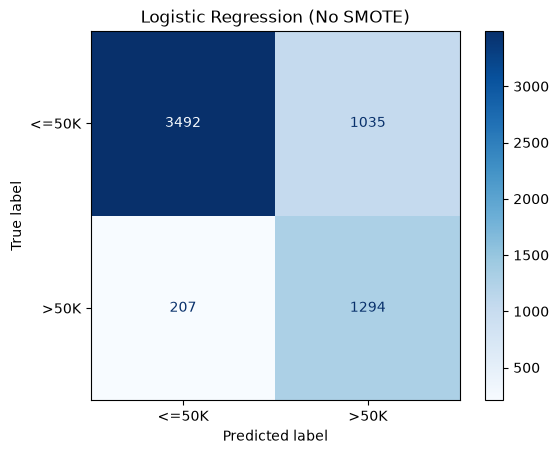

Accuracy:0.787657597876576
Precision:0.5484861781483107
Recall:0.832778147901399
F1:0.6613756613756614


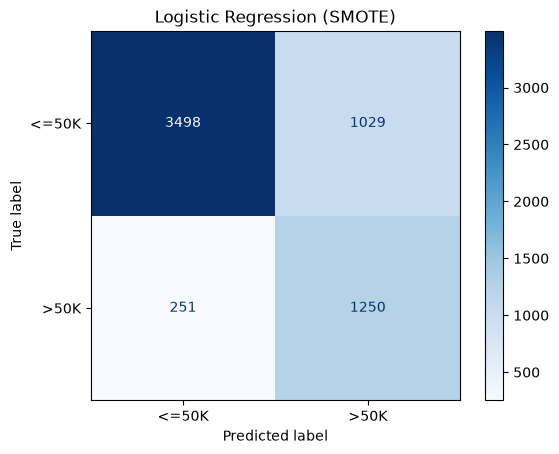

In [60]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

def evaluate_predictions(y_true, y_pred, title="Confusion Matrix"):
    print(f"Accuracy:{accuracy_score(y_true, y_pred)}")
    print(f"Precision:{precision_score(y_true, y_pred)}")
    print(f"Recall:{recall_score(y_true, y_pred)}")
    print(f"F1:{f1_score(y_true, y_pred)}")
    
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["<=50K", ">50K"])
    disp.plot(cmap=plt.cm.Blues)
    plt.title(title)
    plt.show()

evaluate_predictions(y_test, y_pred_no_smote, "Logistic Regression (No SMOTE)")
evaluate_predictions(y_test, y_pred_smote, "Logistic Regression (SMOTE)")

Against the test set, it does not seem like the SMOTE and non-smote training set meaningfully impacted the F1 score. Despite this, during training it appears that the grid search produced a significantly greater (+0.20) F1 score for Smote, suggesting that there may be some overfitting occuring. Next, we will investigate how polynomial terms impact model performance for Logistic regression.

## Model 2B: Logistic Regression with Polynomial Terms
Here we will add polynomial terms with degree 2

In [61]:
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures

num_cols = ['age', 'education.num', 'hours.per.week', 'education.by.hours.worked']

param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "l1_ratio": [0, 0.5, 1],
    "class_weight": [None, "balanced"],
}

poly = PolynomialFeatures(degree=2, include_bias=False)
poly.fit(X_train[num_cols])

def add_poly(X):
    P = poly.transform(X[num_cols])
    names = poly.get_feature_names_out(num_cols)
    P_df = pd.DataFrame(P, columns=names, index=X.index)
    P_df = P_df.drop(columns=num_cols)          # originals are already in X
    return pd.concat([X.drop(columns=num_cols), X[num_cols], P_df], axis=1)

X_train_poly = add_poly(X_train)
X_test_poly = add_poly(X_test)
print(X_train_poly.shape)

X_train_poly_smote = add_poly(X_train_smote)

# Grid search, no smote

grid_no_smote_poly = GridSearchCV(
    LogisticRegression(solver="saga", max_iter=5000),
    param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1,
)

grid_no_smote_poly.fit(X_train_poly, y_train)

print("No SMOTE Poly best params:", grid_no_smote_poly.best_params_)
print("No SMOTE Poly best CV F1:", round(grid_no_smote_poly.best_score_, 4))

# Grid search, with smote

grid_smote_poly = GridSearchCV(
    LogisticRegression(solver="saga", max_iter=5000),
    param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1,
)

grid_smote_poly.fit(X_train_poly_smote, y_train_smote)

print("SMOTE Poly best params:", grid_smote_poly.best_params_)
print("SMOTE Poly best CV F1:", round(grid_smote_poly.best_score_, 4))


(24111, 57)
Fitting 5 folds for each of 30 candidates, totalling 150 fits
No SMOTE Poly best params: {'C': 0.1, 'class_weight': 'balanced', 'l1_ratio': 0}
No SMOTE Poly best CV F1: 0.6702
Fitting 5 folds for each of 30 candidates, totalling 150 fits
SMOTE Poly best params: {'C': 0.1, 'class_weight': None, 'l1_ratio': 1}
SMOTE Poly best CV F1: 0.8332


Accuracy:0.7954545454545454
Precision:0.558008658008658
Recall:0.8587608261159227
F1:0.6764628706376279


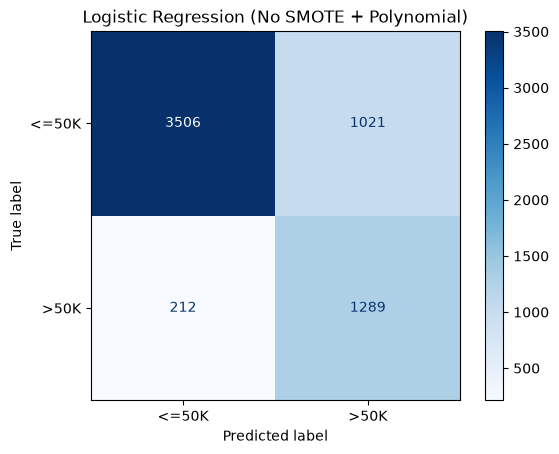

Accuracy:0.7931320504313205
Precision:0.5569506726457399
Recall:0.8274483677548301
F1:0.6657732511391048


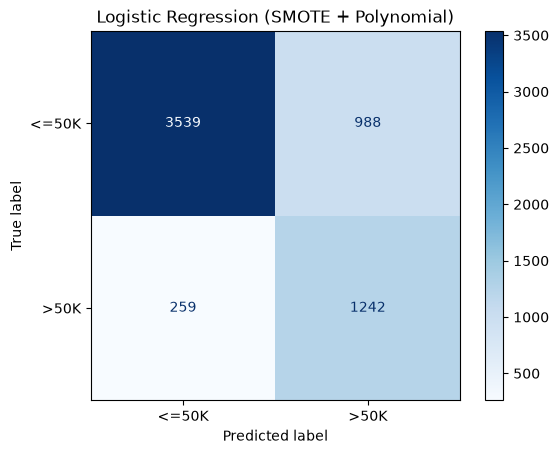

In [62]:
y_pred_no_smote_poly = grid_no_smote_poly.predict(X_test_poly)
y_pred_smote_poly = grid_smote_poly.predict(X_test_poly)

evaluate_predictions(y_test, y_pred_no_smote_poly, "Logistic Regression (No SMOTE + Polynomial)")
evaluate_predictions(y_test, y_pred_smote_poly, "Logistic Regression (SMOTE + Polynomial)")

# Method 2C: Logistic Regression with Forward Feature Selection

In [63]:
from sklearn.feature_selection import SequentialFeatureSelector

best_grid_model = grid_no_smote.best_estimator_

sfs = SequentialFeatureSelector(
    best_grid_model,
    n_features_to_select='auto',
    direction="forward",
    scoring="f1",
    cv=5,
    n_jobs=-1
)

sfs.fit(X_train, y_train)

# Display selected and excluded features
feature_selection = pd.DataFrame({
    "Feature": X_train.columns,
    "Selected": sfs.get_support()
})

print("Selected Features:")
print(feature_selection[feature_selection["Selected"]]["Feature"].tolist())

print("\nExcluded Features:")
print(feature_selection[~feature_selection["Selected"]]["Feature"].tolist())

Selected Features:
['education.num', 'hours.per.week', 'workclass_Self-emp-inc', 'workclass_Without-pay', 'marital.status_Married-AF-spouse', 'marital.status_Married-civ-spouse', 'marital.status_Married-spouse-absent', 'marital.status_Separated', 'occupation_Armed-Forces', 'occupation_Craft-repair', 'occupation_Exec-managerial', 'occupation_Farming-fishing', 'occupation_Machine-op-inspct', 'occupation_Other-service', 'occupation_Priv-house-serv', 'occupation_Protective-serv', 'relationship_Unmarried', 'relationship_Wife', 'sex_Male', 'age_group_young', 'age_group_middle_aged', 'education_category_masters', 'education.by.hours.worked']

Excluded Features:
['age', 'workclass_Local-gov', 'workclass_Private', 'workclass_Self-emp-not-inc', 'workclass_State-gov', 'marital.status_Never-married', 'marital.status_Widowed', 'occupation_Handlers-cleaners', 'occupation_Prof-specialty', 'occupation_Sales', 'occupation_Tech-support', 'occupation_Transport-moving', 'relationship_Not-in-family', 'rela

Accuracy:0.7881552753815527
Precision:0.5495575221238939
Recall:0.8274483677548301
F1:0.6604626429141186


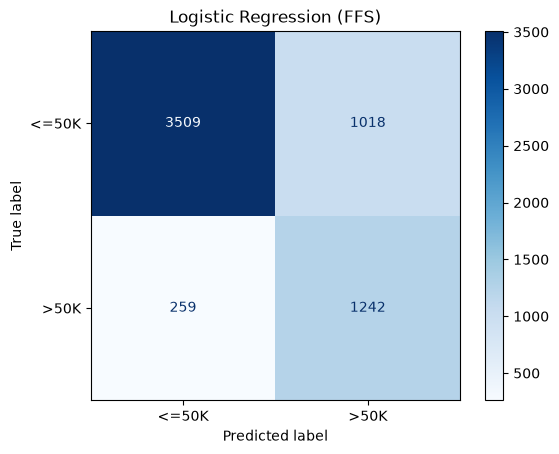

In [64]:
# Get selected features
selected_features = X_train.columns[sfs.get_support()]

# Train model using selected features
best_sfs_model = grid_no_smote.best_estimator_
best_sfs_model.fit(X_train[selected_features], y_train)

# Predict on untouched test set
y_pred_sfs = best_sfs_model.predict(X_test[selected_features])

# Evaluate
evaluate_predictions(y_test, y_pred_sfs, "Logistic Regression (FFS)")

The feature selection reveals that work class, education level, and hours are significant in the model. It also suggests that race is not as important as a feature as initially hypothesized. This model performs similarly to both of the SMOTE/non-SMOTE logistic regression models with an F1 score of 0.66.

# Method 3: Support Vector Machines

              precision    recall  f1-score   support

           0       0.87      0.93      0.90      4527
           1       0.73      0.58      0.65      1501

    accuracy                           0.84      6028
   macro avg       0.80      0.75      0.77      6028
weighted avg       0.84      0.84      0.84      6028



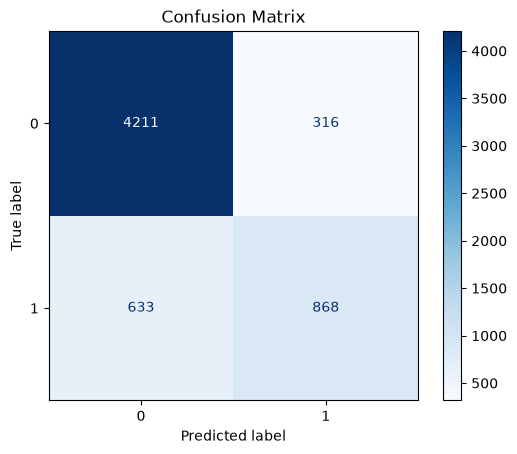

In [65]:
svm_clf = SVC()
svm_clf.fit(X_train, y_train)
test_model(svm_clf)

The default SVM (rbf kernel, C=1) gets 86% accuracy, but it only catches 62% of the people earning more than 50k (recall of 0.62 for class 1). I am going to try other kernels to see if that helps

## Trying different kernels

              precision    recall  f1-score   support

           0       0.87      0.92      0.89      4527
           1       0.70      0.58      0.63      1501

    accuracy                           0.83      6028
   macro avg       0.78      0.75      0.76      6028
weighted avg       0.83      0.83      0.83      6028



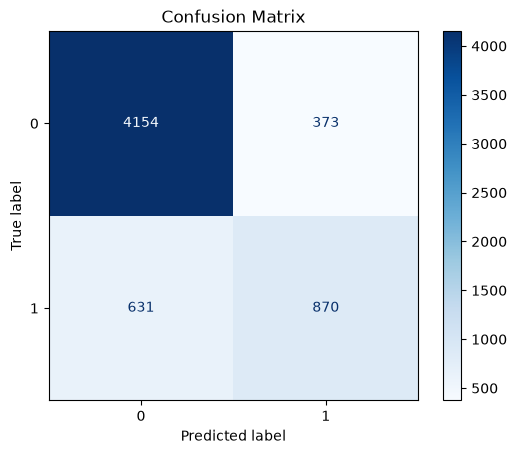

              precision    recall  f1-score   support

           0       0.87      0.93      0.90      4527
           1       0.72      0.56      0.63      1501

    accuracy                           0.84      6028
   macro avg       0.79      0.75      0.76      6028
weighted avg       0.83      0.84      0.83      6028



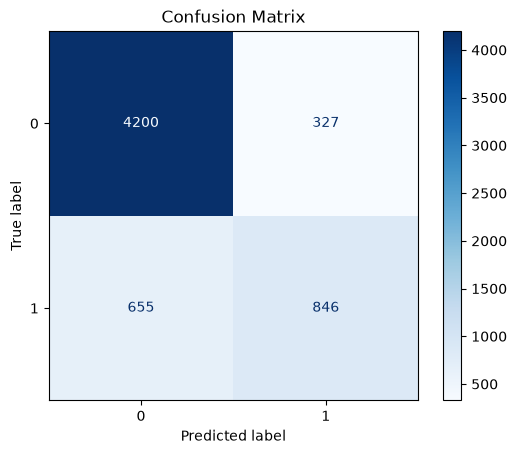

In [66]:
svm_clf = SVC(kernel='linear')
svm_clf.fit(X_train, y_train)
test_model(svm_clf)
svm_clf = SVC(kernel='poly')
svm_clf.fit(X_train, y_train)
test_model(svm_clf)

Neither kernel helped. Linear and polynomial both did slightly worse on the >50k class (F1 of 0.68 compared to 0.69), so I am sticking with rbf

### Trying with class weights balanced

              precision    recall  f1-score   support

           0       0.94      0.77      0.85      4527
           1       0.55      0.85      0.67      1501

    accuracy                           0.79      6028
   macro avg       0.74      0.81      0.76      6028
weighted avg       0.84      0.79      0.80      6028



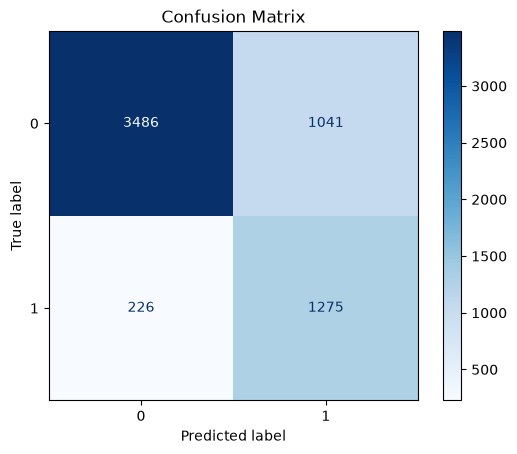

In [67]:
svm_clf = SVC(class_weight='balanced')
svm_clf.fit(X_train, y_train)
test_model(svm_clf)

Balancing the class weights raised the recall for >50k from 0.62 to 0.87, so the model misses far fewer high earners (198 false negatives compared to 575). The tradeoff is a lot more false positives (964 compared to 266) and lower overall accuracy (81% compared to 86%). F1 stayed about the same at 0.69

## Trying different values of C

              precision    recall  f1-score   support

           0       0.94      0.75      0.83      4527
           1       0.53      0.86      0.66      1501

    accuracy                           0.78      6028
   macro avg       0.74      0.81      0.75      6028
weighted avg       0.84      0.78      0.79      6028



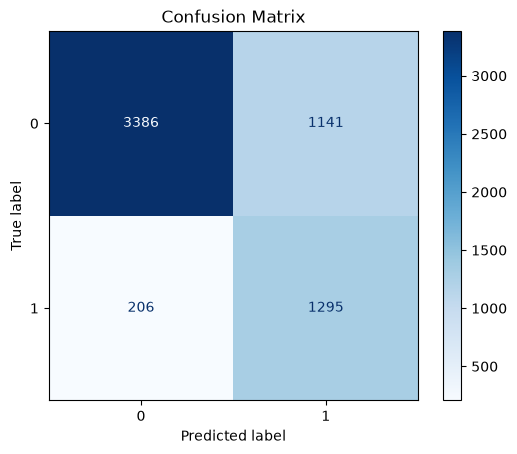

              precision    recall  f1-score   support

           0       0.94      0.77      0.85      4527
           1       0.55      0.85      0.67      1501

    accuracy                           0.79      6028
   macro avg       0.75      0.81      0.76      6028
weighted avg       0.84      0.79      0.80      6028



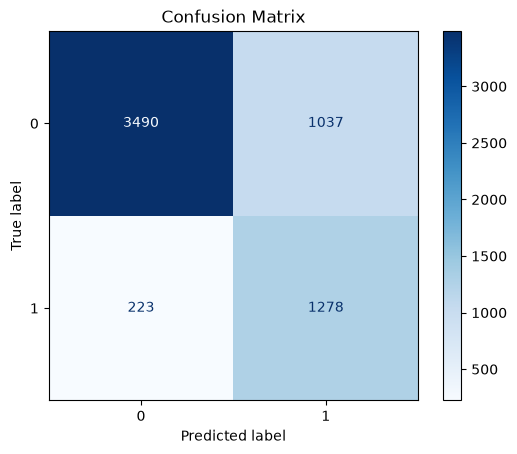

In [68]:
svm_clf = SVC(C=0.1, class_weight='balanced')
svm_clf.fit(X_train, y_train)
test_model(svm_clf)
svm_clf = SVC(C=10, class_weight='balanced')
svm_clf.fit(X_train, y_train)
test_model(svm_clf)

Changing C barely made a difference. C=0.1 dropped accuracy to 80%, and C=10 performed about the same as C=1 while taking longer to train

## Trying different values of gamma

              precision    recall  f1-score   support

           0       0.94      0.73      0.83      4527
           1       0.52      0.86      0.65      1501

    accuracy                           0.77      6028
   macro avg       0.73      0.80      0.74      6028
weighted avg       0.84      0.77      0.78      6028



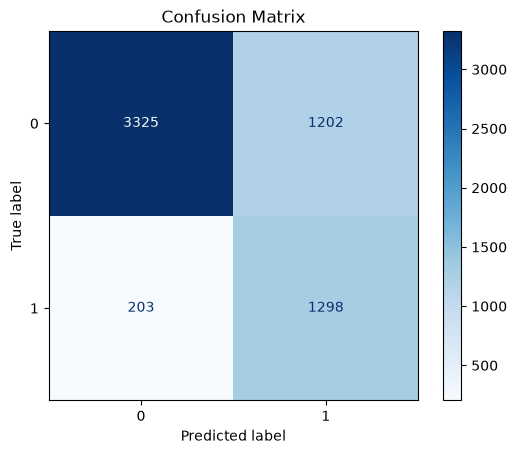

              precision    recall  f1-score   support

           0       0.94      0.77      0.85      4527
           1       0.55      0.85      0.67      1501

    accuracy                           0.79      6028
   macro avg       0.74      0.81      0.76      6028
weighted avg       0.84      0.79      0.80      6028



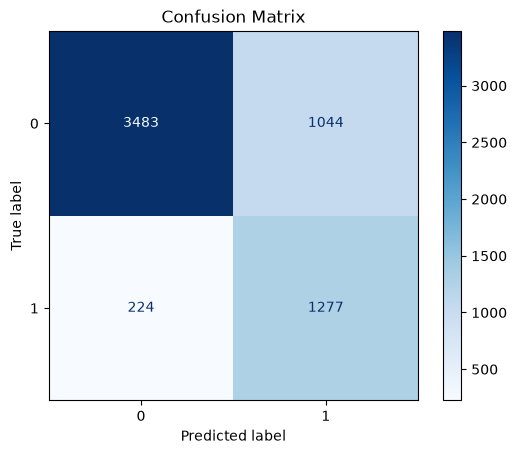

In [69]:
svm_clf = SVC(gamma=0.01, class_weight='balanced')
svm_clf.fit(X_train, y_train)
test_model(svm_clf)
svm_clf = SVC(gamma=0.1, class_weight='balanced')
svm_clf.fit(X_train, y_train)
test_model(svm_clf)

gamma=0.01 was slightly worse. gamma=0.1 gave the exact same results as the default, which makes sense since the default gamma ('scale') works out to roughly 0.1 for this data

## Using Grid Search
To double check the settings I picked by hand, I am running a grid search over the kernel, C and class weights

In [70]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, f1_score

# Define the grid search
param_grid = {
    "C": [0.1, 1, 10], # regularization constant
    "kernel": ["linear", "rbf"], # kernel type
    "class_weight": [None, "balanced"], # penalize according to class unbalance
}

svm_grid = GridSearchCV(
    SVC(),
    param_grid,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=2,
)
svm_grid.fit(X_train, y_train)

print("Best params:", svm_grid.best_params_)
print("Best CV F1:", round(svm_grid.best_score_, 4))

y_pred = svm_grid.best_estimator_.predict(X_test)
print("Test F1:", round(f1_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))


Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best params: {'C': 1, 'class_weight': 'balanced', 'kernel': 'rbf'}
Best CV F1: 0.6644
Test F1: 0.6681
              precision    recall  f1-score   support

           0       0.94      0.77      0.85      4527
           1       0.55      0.85      0.67      1501

    accuracy                           0.79      6028
   macro avg       0.74      0.81      0.76      6028
weighted avg       0.84      0.79      0.80      6028



## Evaluate SVM model

Accuracy:0.789814200398142
Precision:0.5505181347150259
Recall:0.8494337108594271
F1:0.6680639245480744


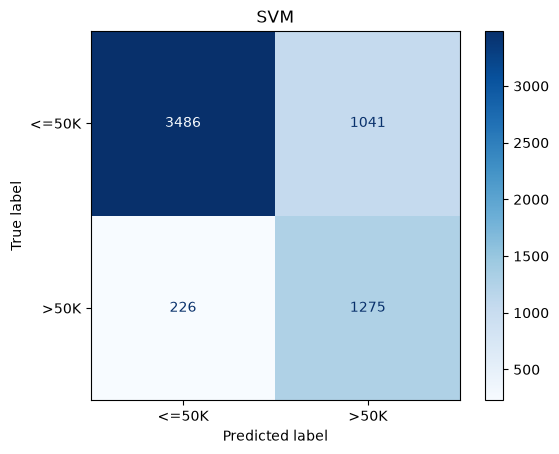

In [71]:
y_pred = svm_grid.best_estimator_.predict(X_test)
evaluate_predictions(y_test, y_pred, "SVM")

The grid search agreed with what I found by hand: the rbf kernel with C=1 and balanced class weights gave the best F1 (0.69 on the test set). It catches 87% of high earners, but only 57% of the people it flags as earning more than 50k actually do

# Method 4: KNN

In [72]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, f1_score

param_grid_knn = {
    "n_neighbors": [3, 5, 7, 11, 15, 21],
    "weights": ["uniform", "distance"],
    "p": [1, 2],  # 1 = manhattan, 2 = euclidean
}

grid_knn_no_smote = GridSearchCV(
    KNeighborsClassifier(),
    param_grid_knn,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1,
)
grid_knn_no_smote.fit(X_train, y_train)
print("KNN no SMOTE best params:", grid_knn_no_smote.best_params_)
print("KNN no SMOTE best CV F1:", round(grid_knn_no_smote.best_score_, 4))

grid_knn_smote = GridSearchCV(
    KNeighborsClassifier(),
    param_grid_knn,
    scoring="f1",
    cv=5,
    n_jobs=-1,
    verbose=1,
)
grid_knn_smote.fit(X_train_smote, y_train_smote)
print("KNN SMOTE best params:", grid_knn_smote.best_params_)
print("KNN SMOTE best CV F1:", round(grid_knn_smote.best_score_, 4))

Fitting 5 folds for each of 24 candidates, totalling 120 fits
KNN no SMOTE best params: {'n_neighbors': 21, 'p': 1, 'weights': 'uniform'}
KNN no SMOTE best CV F1: 0.6477
Fitting 5 folds for each of 24 candidates, totalling 120 fits
KNN SMOTE best params: {'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}
KNN SMOTE best CV F1: 0.8602


Accuracy:0.8349369608493696
Precision:0.6786723163841808
Recall:0.6402398401065956
F1:0.6588961261570107


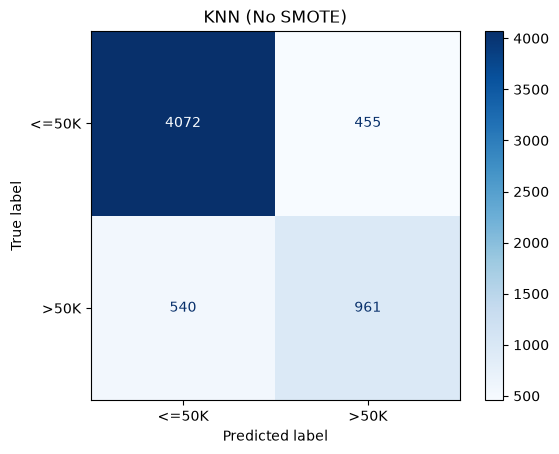

Accuracy:0.7937956204379562
Precision:0.5683262711864406
Recall:0.714856762158561
F1:0.6332251401593391


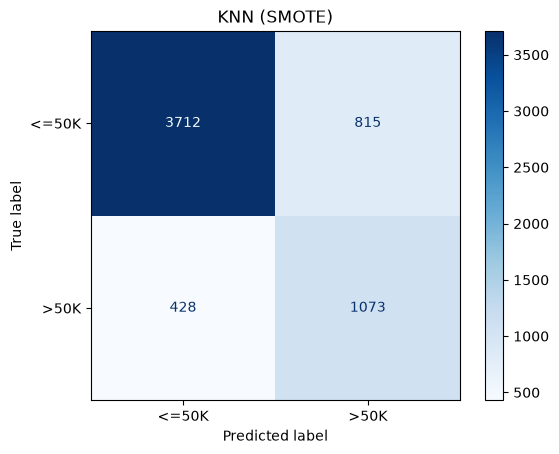

In [73]:
# Final models
best_knn_no_smote = {'n_neighbors': 21, 'p': 1, 'weights': 'uniform'}
best_knn_smote =  {'n_neighbors': 3, 'p': 1, 'weights': 'uniform'}

knn_no_smote = KNeighborsClassifier(**best_knn_no_smote).fit(X_train, y_train)
knn_smote = KNeighborsClassifier(**best_knn_smote).fit(X_train_smote, y_train_smote)

# Compare on the same untouched test set
y_pred_knn_no_smote = knn_no_smote.predict(X_test)
evaluate_predictions(y_test, y_pred_knn_no_smote, "KNN (No SMOTE)")

y_pred_knn_smote = knn_smote.predict(X_test)
evaluate_predictions(y_test, y_pred_knn_smote, "KNN (SMOTE)")

It appears that for KNN, SMOTE performs better on the Training set than the test set, suggesting there to be some overfitting. Against the test set, the model with SMOTE performs slightly worse.